# NB19: Post-Processing, Visualization & Model Evaluation

**Purpose**: Generate two synthetic forcing experiments with actual RELIC kernels, visualize their outputs, and compare a perturbed candidate against a model reference. No observed site data are used.

This is the RELIC equivalent of WRF's NCL/Python post-processing tutorials
and CMAQ's evaluation toolkit (AMET).

**Time**: ~5 minutes


## Architecture Anchor

This notebook follows `docs\source\architecture_overview.md`. It calls actual Functor kernels directly and advances the bucket state in a notebook-local loop. It does not run the governed simulator or demonstrate StateManager commits. Decomposition pools are held fixed for diagnostic probes. The final carbon calculation is a deliberately constructed budget example, not an independent conservation audit of a coupled ecosystem simulation.


In [1]:
# Use only the standard library so notebook execution stays self-contained on Windows.
import asyncio
if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

# ---------------------------------------------------------------
# References:
#   Taylor (2001), JGR -- Taylor diagram for model evaluation
#   Willmott (1982) -- Index of agreement
#   RELIC functors used below: FarquharPhotosynthesis, PenmanMonteithET,
#   BucketSoilMoisture, FirstOrderDecomposition
# Mathematical expression:
#   RMSE = sqrt(mean((candidate - reference)^2))
#   R2 = corr(candidate, reference)^2
#   NSE = 1 - sum((candidate - reference)^2) / sum((reference - mean(reference))^2)
# Parameter meanings:
#   reference: baseline RELIC run used as evaluation target
#   candidate: perturbed RELIC kernel experiment used for comparison.
# Units: GPP [kg C m-2 s-1], ET [kg m-2 s-1], dark respiration [umol CO2 m-2 s-1].
# Domain/constraints: synthetic hourly forcing; no observational validation or coupled carbon-state advance.
# Sign convention: GPP is positive uptake; ET is positive water loss.
# ---------------------------------------------------------------

import os
import sys
import warnings
from pathlib import Path

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

# Suppress the environment-specific torch CUDA pynvml deprecation warning only.
warnings.filterwarnings(
    "ignore",
    message="The pynvml package is deprecated.*",
    category=FutureWarning,
    module=r"torch\.cuda\.__init__",
)


def locate_project_root() -> Path:
    candidates = [
        Path(os.environ.get("RELIC_PROJECT_ROOT", Path.cwd())).resolve(),
        Path.cwd(),
        Path.cwd().parent,
    ]
    for candidate in candidates:
        if (candidate / "relic").exists() and (candidate / "docs").exists():
            return candidate.resolve()
    raise RuntimeError("Could not locate RELIC project root.")


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import torch

from relic.validation import quick_validate
from relic.scientific.biosphere.photosynthesis.farquhar import FarquharPhotosynthesis
from relic.scientific.hydrosphere.evapotranspiration.penman_monteith import PenmanMonteithET
from relic.scientific.hydrosphere.soil_moisture.bucket import BucketSoilMoisture
from relic.scientific.pedosphere.decomposition.first_order import FirstOrderDecomposition


def unwrap_update(value):
    return value.value if hasattr(value, "value") else value

n_hours = 24 * 30
hours = torch.arange(n_hours, dtype=torch.float32)
days = hours / 24.0
hour_of_day = hours % 24.0

# References: RELIC tutorial forcing convention; these are not measured weather data.
# Mathematical expression: daytime = max(sin(pi*(hour-6)/12), 0).
# Parameter meanings: amplitudes and phase offsets define the illustrative forcing experiment.
# Units: PPFD [umol m-2 s-1], temperature [K], VPD series [kPa], precipitation [kg m-2 s-1].
# Domain/constraints: 30 days of hourly inputs; convert VPD from kPa to Pa at each kernel boundary.
# Sign convention: positive precipitation adds water; positive VPD is an atmospheric deficit.
par_series = 1500.0 * torch.clamp(torch.sin(torch.pi * (hour_of_day - 6.0) / 12.0), min=0.0)
net_radiation_series = 90.0 + 220.0 * torch.clamp(torch.sin(torch.pi * (hour_of_day - 6.0) / 12.0), min=0.0)
air_temperature_series = 289.15 + 6.0 * torch.sin(2.0 * torch.pi * (hour_of_day - 5.0) / 24.0) + 1.5 * torch.sin(2.0 * torch.pi * days / 30.0)
vpd_series = 0.6 + 1.6 * torch.clamp(torch.sin(torch.pi * (hour_of_day - 7.0) / 12.0), min=0.0)
precipitation_flux_series = torch.zeros(n_hours, dtype=torch.float32)
precipitation_flux_series[36:48] = 0.0008
precipitation_flux_series[188:202] = 0.0012
precipitation_flux_series[420:432] = 0.0006

photosynthesis_reference = FarquharPhotosynthesis(name="tutorial_farquhar_reference")
photosynthesis_candidate = FarquharPhotosynthesis(name="tutorial_farquhar_candidate")
et_reference_functor = PenmanMonteithET(name="tutorial_et_reference", config={"canopy_resistance_source": "state"})
et_candidate_functor = PenmanMonteithET(name="tutorial_et_candidate", config={"canopy_resistance_source": "state"})
bucket_reference = BucketSoilMoisture(name="tutorial_bucket_reference")
bucket_candidate = BucketSoilMoisture(name="tutorial_bucket_candidate")
decomposition_functor = FirstOrderDecomposition(
    name="tutorial_decomposition_reference",
    config={
        "k_metabolic": 10.0,
        "k_structural": 4.9,
        "k_fast_som": 6.0,
        "k_slow_som": 0.2,
        "k_passive_som": 0.0045,
        "q10_decomposition": 2.0,
        "lignin_n_threshold": 0.45,
        "clay_content": 0.25,
        "temp_response_type": "q10",
        "moisture_response_power": 1.0,
        "field_capacity": 0.25,
        "wilting_point": 0.10,
        "t_met_fast": 0.45,
        "t_met_slow": 0.45,
        "t_str_fast": 0.40,
        "t_str_slow": 0.40,
        "t_fast_slow": 0.42,
        "t_fast_passive": 0.03,
        "t_slow_fast": 0.45,
        "t_slow_passive": 0.03,
    },
)

soil_moisture_reference_state = torch.tensor(0.28, dtype=torch.float32)
soil_moisture_candidate_state = torch.tensor(0.22, dtype=torch.float32)

gpp_reference = []
gpp_candidate = []
et_reference = []
et_candidate = []
soil_moisture_reference = [soil_moisture_reference_state.detach().clone()]
soil_moisture_candidate = [soil_moisture_candidate_state.detach().clone()]
dark_respiration_reference = []
dark_respiration_candidate = []
heterotrophic_respiration_reference = []
heterotrophic_respiration_candidate = []

for idx in range(n_hours):
    current_temperature = air_temperature_series[idx]
    current_precipitation = precipitation_flux_series[idx]
    current_vpd = vpd_series[idx]
    current_par = par_series[idx]
    current_net_radiation = net_radiation_series[idx]

    et_reference_updates = et_reference_functor.forward(
        {
            "net_radiation": current_net_radiation,
            "air_temperature": current_temperature,
            "wind_speed": torch.tensor(2.0, dtype=torch.float32),
            "atmospheric_pressure": torch.tensor(101325.0, dtype=torch.float32),
            "relative_humidity": torch.tensor(0.60, dtype=torch.float32),
            "vapor_pressure_deficit": current_vpd * 1000.0,
            "surface_resistance": torch.tensor(90.0, dtype=torch.float32),
            "stomatal_conductance": torch.tensor(0.012, dtype=torch.float32),
            "canopy_conductance": torch.tensor(0.012, dtype=torch.float32),
            "aerodynamic_resistance": torch.tensor(45.0, dtype=torch.float32),
        },
        time=float(idx) * 3600.0,
        dt=3600.0,
    )
    et_candidate_updates = et_candidate_functor.forward(
        {
            "net_radiation": current_net_radiation,
            "air_temperature": current_temperature,
            "wind_speed": torch.tensor(2.0, dtype=torch.float32),
            "atmospheric_pressure": torch.tensor(101325.0, dtype=torch.float32),
            "relative_humidity": torch.tensor(0.60, dtype=torch.float32),
            "vapor_pressure_deficit": current_vpd * 1000.0,
            "surface_resistance": torch.tensor(140.0, dtype=torch.float32),
            "stomatal_conductance": torch.tensor(0.009, dtype=torch.float32),
            "canopy_conductance": torch.tensor(0.009, dtype=torch.float32),
            "aerodynamic_resistance": torch.tensor(45.0, dtype=torch.float32),
        },
        time=float(idx) * 3600.0,
        dt=3600.0,
    )
    et_reference_flux = unwrap_update(et_reference_updates["evapotranspiration_flux"]).detach().to(dtype=torch.float32)
    et_candidate_flux = unwrap_update(et_candidate_updates["evapotranspiration_flux"]).detach().to(dtype=torch.float32)

    bucket_reference_updates = bucket_reference.forward(
        {
            "soil_moisture": soil_moisture_reference_state,
            "precipitation_flux": current_precipitation,
            "evapotranspiration_flux": et_reference_flux,
            "air_temperature": current_temperature,
        },
        time=float(idx) * 3600.0,
        dt=3600.0,
    )
    bucket_candidate_updates = bucket_candidate.forward(
        {
            "soil_moisture": soil_moisture_candidate_state,
            "precipitation_flux": current_precipitation,
            "evapotranspiration_flux": et_candidate_flux,
            "air_temperature": current_temperature,
        },
        time=float(idx) * 3600.0,
        dt=3600.0,
    )
    soil_moisture_reference_state = unwrap_update(bucket_reference_updates["soil_moisture"]).detach().to(dtype=torch.float32)
    soil_moisture_candidate_state = unwrap_update(bucket_candidate_updates["soil_moisture"]).detach().to(dtype=torch.float32)

    # References: RELIC tutorial linear stress convention, not a calibrated stress model.
    # Mathematical expression: stress = clip((theta-0.10)/0.20, 0, 1); psi = -0.4-(1-stress).
    # Parameter meanings: theta is the bucket moisture; the endpoints are teaching choices.
    # Units: theta/stress [1], leaf water potential psi [MPa].
    # Domain/constraints: normalize stress to [0,1]; no additional process owner is registered.
    # Sign convention: larger stress factor means less water limitation; psi is negative.
    water_stress_reference = torch.clamp((soil_moisture_reference_state - 0.10) / 0.20, min=0.0, max=1.0)
    water_stress_candidate = torch.clamp((soil_moisture_candidate_state - 0.10) / 0.20, min=0.0, max=1.0)
    leaf_water_potential_reference = -0.4 - (1.0 - water_stress_reference) * 1.0
    leaf_water_potential_candidate = -0.4 - (1.0 - water_stress_candidate) * 1.0

    gpp_reference_updates = photosynthesis_reference.forward(
        {
            "air_temperature": current_temperature,
            "atmospheric_co2_ppm": torch.tensor(410.0, dtype=torch.float32),
            "ppfd": current_par,
            "vcmax_scaling": torch.tensor(1.0, dtype=torch.float32),
            "jmax_scaling": torch.tensor(1.0, dtype=torch.float32),
            "water_stress_factor": water_stress_reference,
            "temperature_stress_factor": torch.tensor(1.0, dtype=torch.float32),
            "ozone_stress_factor": torch.tensor(1.0, dtype=torch.float32),
            "vapor_pressure_deficit": current_vpd * 1000.0,
            "leaf_area_index": torch.tensor(3.2, dtype=torch.float32),
            "leaf_water_potential": leaf_water_potential_reference,
        },
        time=float(idx) * 3600.0,
        dt=3600.0,
    )
    gpp_candidate_updates = photosynthesis_candidate.forward(
        {
            "air_temperature": current_temperature,
            "atmospheric_co2_ppm": torch.tensor(410.0, dtype=torch.float32),
            "ppfd": current_par,
            "vcmax_scaling": torch.tensor(0.95, dtype=torch.float32),
            "jmax_scaling": torch.tensor(0.95, dtype=torch.float32),
            "water_stress_factor": water_stress_candidate,
            "temperature_stress_factor": torch.tensor(1.0, dtype=torch.float32),
            "ozone_stress_factor": torch.tensor(1.0, dtype=torch.float32),
            "vapor_pressure_deficit": current_vpd * 1000.0,
            "leaf_area_index": torch.tensor(2.8, dtype=torch.float32),
            "leaf_water_potential": leaf_water_potential_candidate,
        },
        time=float(idx) * 3600.0,
        dt=3600.0,
    )
    gpp_reference_flux = unwrap_update(gpp_reference_updates["gross_primary_productivity"]).detach().to(dtype=torch.float32)
    gpp_candidate_flux = unwrap_update(gpp_candidate_updates["gross_primary_productivity"]).detach().to(dtype=torch.float32)
    dark_respiration_reference_flux = unwrap_update(gpp_reference_updates["diagnostics.photosynthesis.dark_respiration"]).detach().to(dtype=torch.float32)
    dark_respiration_candidate_flux = unwrap_update(gpp_candidate_updates["diagnostics.photosynthesis.dark_respiration"]).detach().to(dtype=torch.float32)

    decomposition_reference_updates = decomposition_functor.forward(
        {
            "metabolic_litter_c": torch.tensor(0.10, dtype=torch.float32),
            "structural_litter_c": torch.tensor(0.50, dtype=torch.float32),
            "fast_som_c": torch.tensor(0.80, dtype=torch.float32),
            "slow_som_c": torch.tensor(3.00, dtype=torch.float32),
            "passive_som_c": torch.tensor(5.00, dtype=torch.float32),
            "soil_temperature": current_temperature - 1.5,
            "soil_moisture": soil_moisture_reference_state,
            "lignin_n_ratio": torch.tensor(0.20, dtype=torch.float32),
            "clay_content": torch.tensor(0.25, dtype=torch.float32),
            "metabolic_litter_input": torch.tensor(0.0, dtype=torch.float32),
            "structural_litter_input": torch.tensor(0.0, dtype=torch.float32),
        },
        time=float(idx) * 3600.0,
        dt=3600.0,
    )
    decomposition_candidate_updates = decomposition_functor.forward(
        {
            "metabolic_litter_c": torch.tensor(0.10, dtype=torch.float32),
            "structural_litter_c": torch.tensor(0.50, dtype=torch.float32),
            "fast_som_c": torch.tensor(0.80, dtype=torch.float32),
            "slow_som_c": torch.tensor(3.00, dtype=torch.float32),
            "passive_som_c": torch.tensor(5.00, dtype=torch.float32),
            "soil_temperature": current_temperature - 1.5,
            "soil_moisture": soil_moisture_candidate_state,
            "lignin_n_ratio": torch.tensor(0.20, dtype=torch.float32),
            "clay_content": torch.tensor(0.25, dtype=torch.float32),
            "metabolic_litter_input": torch.tensor(0.0, dtype=torch.float32),
            "structural_litter_input": torch.tensor(0.0, dtype=torch.float32),
        },
        time=float(idx) * 3600.0,
        dt=3600.0,
    )
    heterotrophic_respiration_reference_flux = unwrap_update(decomposition_reference_updates["heterotrophic_respiration"]).detach().to(dtype=torch.float32)
    heterotrophic_respiration_candidate_flux = unwrap_update(decomposition_candidate_updates["heterotrophic_respiration"]).detach().to(dtype=torch.float32)

    gpp_reference.append(gpp_reference_flux)
    gpp_candidate.append(gpp_candidate_flux)
    et_reference.append(et_reference_flux)
    et_candidate.append(et_candidate_flux)
    soil_moisture_reference.append(soil_moisture_reference_state.detach().clone())
    soil_moisture_candidate.append(soil_moisture_candidate_state.detach().clone())
    dark_respiration_reference.append(dark_respiration_reference_flux)
    dark_respiration_candidate.append(dark_respiration_candidate_flux)
    heterotrophic_respiration_reference.append(heterotrophic_respiration_reference_flux)
    heterotrophic_respiration_candidate.append(heterotrophic_respiration_candidate_flux)

gpp_reference = torch.stack(gpp_reference)
gpp_candidate = torch.stack(gpp_candidate)
et_reference = torch.stack(et_reference)
et_candidate = torch.stack(et_candidate)
soil_moisture_reference = torch.stack(soil_moisture_reference)
soil_moisture_candidate = torch.stack(soil_moisture_candidate)
dark_respiration_reference = torch.stack(dark_respiration_reference)
dark_respiration_candidate = torch.stack(dark_respiration_candidate)
heterotrophic_respiration_reference = torch.stack(heterotrophic_respiration_reference)
heterotrophic_respiration_candidate = torch.stack(heterotrophic_respiration_candidate)

daily_gpp_reference = gpp_reference.reshape(-1, 24).mean(dim=1)
daily_gpp_candidate = gpp_candidate.reshape(-1, 24).mean(dim=1)
daily_et_reference = et_reference.reshape(-1, 24).mean(dim=1)
daily_et_candidate = et_candidate.reshape(-1, 24).mean(dim=1)
daily_dark_respiration_reference = dark_respiration_reference.reshape(-1, 24).mean(dim=1)
daily_dark_respiration_candidate = dark_respiration_candidate.reshape(-1, 24).mean(dim=1)

print("=== RELIC Kernel Reference and Candidate Experiments Generated ===")
print(f"  Duration: {n_hours} hours ({n_hours/24:.0f} days)")
print(f"  GPP reference range:  {torch.min(gpp_reference).item():.3e} to {torch.max(gpp_reference).item():.3e} kg C m-2 s-1")
print(f"  GPP candidate range:  {torch.min(gpp_candidate).item():.3e} to {torch.max(gpp_candidate).item():.3e} kg C m-2 s-1")
print(f"  ET reference range:   {torch.min(et_reference).item():.6f} to {torch.max(et_reference).item():.6f} kg m-2 s-1")
print(f"  ET candidate range:   {torch.min(et_candidate).item():.6f} to {torch.max(et_candidate).item():.6f} kg m-2 s-1")
print(f"  Soil moisture reference final: {soil_moisture_reference[-1].item():.4f}")
print(f"  Soil moisture candidate final: {soil_moisture_candidate[-1].item():.4f}")
assert torch.isfinite(gpp_reference).all() and torch.isfinite(gpp_candidate).all()
assert torch.isfinite(et_reference).all() and torch.isfinite(et_candidate).all()
print("  [OK] Finite kernel outputs generated; this is not a governed simulator run.")

=== RELIC Kernel Reference and Candidate Experiments Generated ===
  Duration: 720 hours (30 days)
  GPP reference range:  0.000e+00 to 2.156e-07 kg C m-2 s-1
  GPP candidate range:  0.000e+00 to 1.787e-07 kg C m-2 s-1
  ET reference range:   0.000027 to 0.000086 kg m-2 s-1
  ET candidate range:   0.000022 to 0.000072 kg m-2 s-1
  Soil moisture reference final: 0.2362
  Soil moisture candidate final: 0.2381
  [OK] Finite kernel outputs generated; this is not a governed simulator run.


## Statistical Evaluation Metrics

The candidate is compared with another model experiment, not observations. Bias, RMSE, and MAE retain the GPP units `kg C m-2 s-1`; correlation, squared correlation, NSE, and agreement are dimensionless. This demonstrates calculation and interpretation, not field validation.


In [2]:
# ---------------------------------------------------------------
# References:
#   Nash & Sutcliffe (1970) -- model efficiency
#   Taylor (2001) -- pattern statistics
#   relic.validation.cross_domain_validator -- RELIC built-in validation
# Mathematical expression:
#   RMSE = sqrt(mean((candidate - reference)^2))
#   NSE = 1 - sum((candidate - reference)^2) / sum((reference - mean(reference))^2)
# Parameter meanings:
#   candidate: candidate RELIC run values (torch tensor)
#   reference: reference RELIC kernel values (torch tensor).
# Units: errors retain input units; R, R2, NSE, and d are dimensionless.
# Domain/constraints: paired finite series with nonzero variance and agreement denominator.
# Sign convention: positive bias is candidate minus reference.
# ---------------------------------------------------------------

# The equations below illustrate descriptive metrics; no model-validation report is produced.

def compute_metrics(candidate, reference):
    """Compute standard evaluation metrics for actual RELIC outputs."""
    residuals = candidate - reference
    bias = torch.mean(residuals)
    rmse = torch.sqrt(torch.mean(residuals**2))
    mae = torch.mean(torch.abs(residuals))
    r = torch.corrcoef(torch.stack([candidate, reference]))[0, 1]
    r2 = r**2
    ss_res = torch.sum((candidate - reference)**2)
    ss_tot = torch.sum((reference - torch.mean(reference))**2)
    nse = 1.0 - ss_res / ss_tot if ss_tot > 0 else float('nan')
    d = 1.0 - ss_res / torch.sum((torch.abs(candidate - torch.mean(reference)) + torch.abs(reference - torch.mean(reference)))**2)
    return {
        "Bias": bias, "RMSE": rmse, "MAE": mae,
        "R": r, "R2": r2, "NSE": nse, "d": d,
    }

metrics = compute_metrics(gpp_candidate, gpp_reference)

print("=== Candidate vs Reference Evaluation Metrics ===")
print()
print(f"  {'Metric':<10s} {'Value':>10s} {'Ideal':>10s} {'Interpretation'}")
print("  " + "-" * 65)
print(f"  {'Bias':<10s} {metrics['Bias']:10.3e} {'0.0':>10s}  Systematic offset")
print(f"  {'RMSE':<10s} {metrics['RMSE']:10.3e} {'0.0':>10s}  Overall error magnitude")
print(f"  {'MAE':<10s} {metrics['MAE']:10.3e} {'0.0':>10s}  Mean absolute error")
print(f"  {'R':<10s} {metrics['R']:10.3f} {'1.0':>10s}  Linear correlation")
print(f"  {'R2':<10s} {metrics['R2']:10.3f} {'1.0':>10s}  Squared correlation")
print(f"  {'NSE':<10s} {metrics['NSE']:10.3f} {'1.0':>10s}  Nash-Sutcliffe efficiency")
print(f"  {'d':<10s} {metrics['d']:10.3f} {'1.0':>10s}  Willmott agreement")

print("\n=== RELIC quick_validate Integration ===")
checker = quick_validate
print(f"  quick_validate callable: {callable(checker)}")
print("  Governed-run usage: report = quick_validate(state_manager=state_manager)")
print("  [OK] API import checked; quick_validate was not executed in this notebook.")


=== Candidate vs Reference Evaluation Metrics ===

  Metric          Value      Ideal Interpretation
  -----------------------------------------------------------------
  Bias       -1.330e-08        0.0  Systematic offset
  RMSE        2.328e-08        0.0  Overall error magnitude
  MAE         1.330e-08        0.0  Mean absolute error
  R               0.985        1.0  Linear correlation
  R2              0.970        1.0  Squared correlation
  NSE             0.910        1.0  Nash-Sutcliffe efficiency
  d               0.973        1.0  Willmott agreement

=== RELIC quick_validate Integration ===
  quick_validate callable: True
  Governed-run usage: report = quick_validate(state_manager=state_manager)
  [OK] API import checked; quick_validate was not executed in this notebook.


## Diurnal Cycle Analysis

Extract and compare the mean diurnal cycle -- the most basic diagnostic
for ecosystem models.


In [3]:
# ---------------------------------------------------------------
# References:
#   Baldocchi et al. (2001) -- FLUXNET diurnal analysis
# Mathematical expression:
#   GPP_diurnal(h) = mean(GPP[hour_of_day == h]) for h in 0..23
# Parameter meanings:
#   h: hour of day (0-23).
# Units: GPP mean and standard deviation [kg C m-2 s-1].
# Domain/constraints: paired hourly samples with multiple days per hour bin.
# Sign convention: positive GPP is carbon uptake; differences are candidate minus reference.
# ---------------------------------------------------------------

diurnal_reference = torch.zeros(24, dtype=torch.float32)
diurnal_candidate = torch.zeros(24, dtype=torch.float32)
diurnal_std_reference = torch.zeros(24, dtype=torch.float32)
diurnal_std_candidate = torch.zeros(24, dtype=torch.float32)

for h in range(24):
    mask = (hours % 24) == h
    diurnal_reference[h] = gpp_reference[mask].mean()
    diurnal_candidate[h] = gpp_candidate[mask].mean()
    diurnal_std_reference[h] = gpp_reference[mask].std()
    diurnal_std_candidate[h] = gpp_candidate[mask].std()

print("=== Mean Diurnal GPP from RELIC Kernels [kg C m-2 s-1] ===")
print()
print(f"  {'Hour':<6s} {'Reference':>10s} {'Candidate':>10s} {'Diff':>10s}")
print("  " + "-" * 46)
for h in range(24):
    diff = diurnal_candidate[h] - diurnal_reference[h]
    print(f"  {h:>4d}h  {diurnal_reference[h]:10.3e} {diurnal_candidate[h]:10.3e} {diff:+10.3e}")

peak_reference = torch.argmax(diurnal_reference)
peak_candidate = torch.argmax(diurnal_candidate)
print()
print(f"  Peak hour: reference={int(peak_reference)}h, candidate={int(peak_candidate)}h")
print(f"  Peak GPP:  reference={float(diurnal_reference[peak_reference]):.3e}, candidate={float(diurnal_candidate[peak_candidate]):.3e} kg C m-2 s-1")


=== Mean Diurnal GPP from RELIC Kernels [kg C m-2 s-1] ===

  Hour    Reference  Candidate       Diff
  ----------------------------------------------
     0h   0.000e+00  0.000e+00 +0.000e+00
     1h   0.000e+00  0.000e+00 +0.000e+00
     2h   0.000e+00  0.000e+00 +0.000e+00
     3h   0.000e+00  0.000e+00 +0.000e+00
     4h   0.000e+00  0.000e+00 +0.000e+00
     5h   0.000e+00  0.000e+00 +0.000e+00
     6h   0.000e+00  0.000e+00 +0.000e+00
     7h   1.585e-07  1.302e-07 -2.826e-08
     8h   1.828e-07  1.482e-07 -3.456e-08
     9h   1.780e-07  1.437e-07 -3.429e-08
    10h   1.686e-07  1.358e-07 -3.278e-08
    11h   1.598e-07  1.286e-07 -3.119e-08
    12h   1.528e-07  1.229e-07 -2.986e-08
    13h   1.475e-07  1.187e-07 -2.880e-08
    14h   1.432e-07  1.153e-07 -2.790e-08
    15h   1.391e-07  1.122e-07 -2.691e-08
    16h   1.323e-07  1.072e-07 -2.512e-08
    17h   1.094e-07  8.977e-08 -1.958e-08
    18h   0.000e+00  0.000e+00 +0.000e+00
    19h   0.000e+00  0.000e+00 +0.000e+00
    20h  

## Output Diagnostics and a Constructed Budget Example

The plots compare the two kernel experiments. The subsequent budget cell converts the actual flux units and supplies a synthetic final storage to `ConservationGuardian`. Its residual checks this constructed ledger only; independently committed initial and final states would be required to audit a real simulation.


=== Post-Processing Evaluation ===


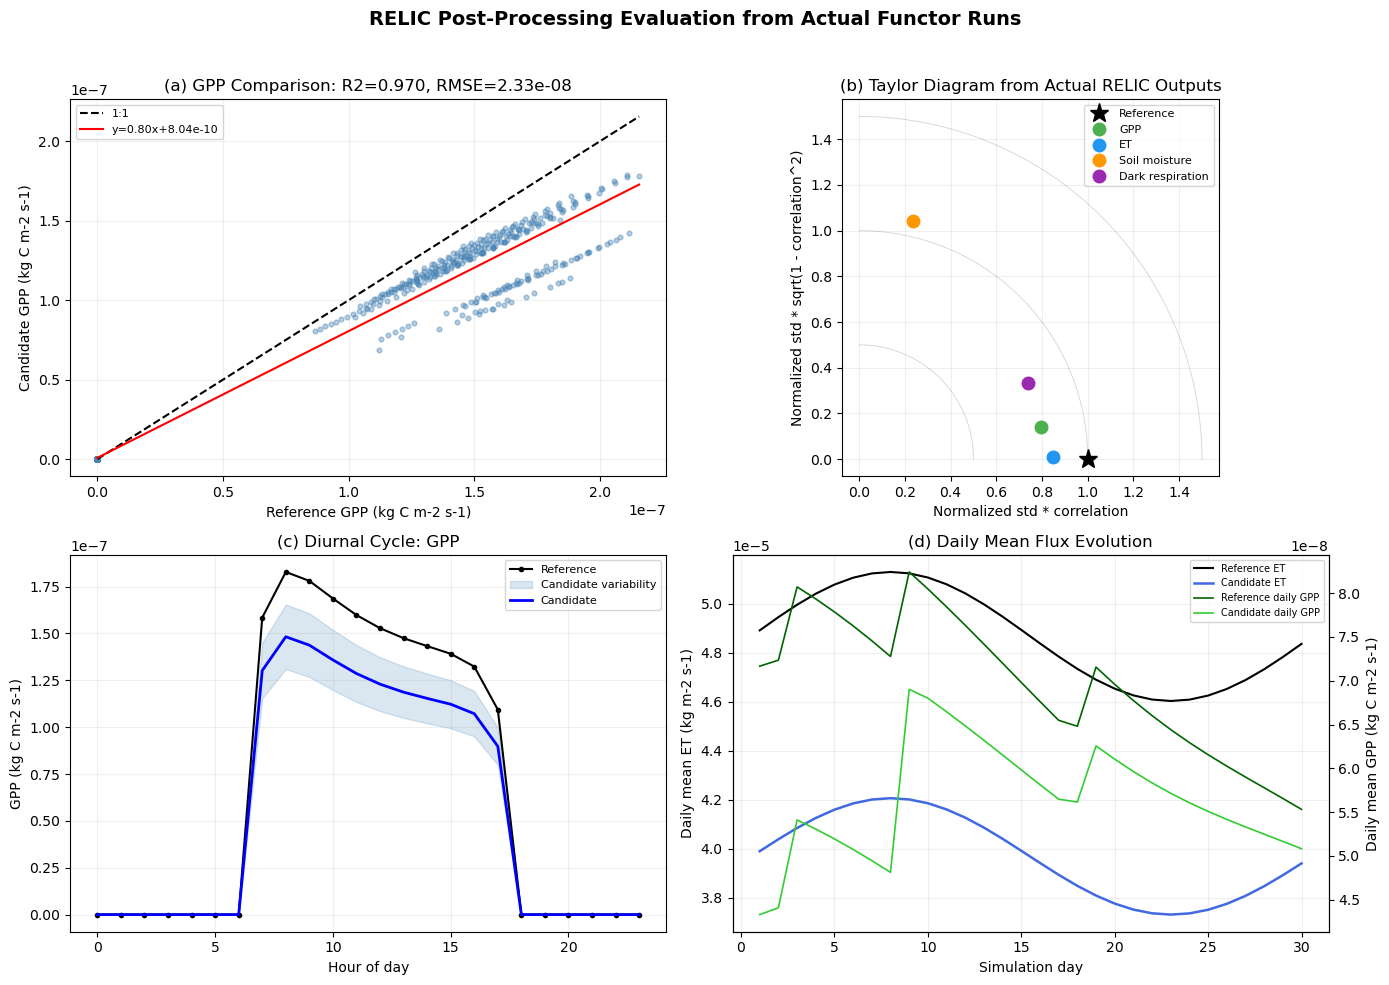

[OK] Post-processing evaluation visualization


In [4]:
# === NB19: Post-Processing Evaluation Visualization ===
# References:
# - Taylor (2001) pattern statistics for model comparison.
# - Baldocchi et al. (2001) diurnal aggregation for ecosystem fluxes.
# Mathematical expression:
# - std_ratio = std(candidate) / std(reference)
# - corr = corrcoef(candidate, reference)
# - daily_mean = mean(x over 24-hour blocks)
# Parameter meanings:
# - reference: baseline RELIC run output.
# - candidate: perturbed RELIC kernel output.
# Units: GPP [kg C m-2 s-1], ET [kg m-2 s-1]; normalized Taylor coordinates [1].
# Domain/constraints: finite paired series with nonzero standard deviations.
# Sign convention: positive GPP is uptake; positive ET is water loss.

import matplotlib.pyplot as plt
import torch

print("=== Post-Processing Evaluation ===")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: Candidate vs reference scatter for GPP
ax = axes[0, 0]
ax.scatter(gpp_reference.tolist(), gpp_candidate.tolist(), c="steelblue", alpha=0.4, s=12)
scatter_min = float(torch.min(torch.cat([gpp_reference, gpp_candidate])))
scatter_max = float(torch.max(torch.cat([gpp_reference, gpp_candidate])))
ax.plot([scatter_min, scatter_max], [scatter_min, scatter_max], "k--", label="1:1")
# Float64 preserves the rank of the small mass-flux column beside the unit intercept.
regression_matrix = torch.stack([gpp_reference, torch.ones_like(gpp_reference)], dim=1).to(torch.float64)
regression_solution = torch.linalg.lstsq(regression_matrix, gpp_candidate.to(torch.float64)).solution
slope = float(regression_solution[0])
intercept = float(regression_solution[1])
ax.plot([scatter_min, scatter_max], [slope * scatter_min + intercept, slope * scatter_max + intercept], "r-", label=f"y={slope:.2f}x+{intercept:.2e}")
r2 = torch.corrcoef(torch.stack([gpp_reference, gpp_candidate]))[0, 1] ** 2
rmse = torch.sqrt(torch.mean((gpp_candidate - gpp_reference) ** 2))
ax.set_xlabel("Reference GPP (kg C m-2 s-1)")
ax.set_ylabel("Candidate GPP (kg C m-2 s-1)")
ax.set_title(f"(a) GPP Comparison: R2={float(r2):.3f}, RMSE={float(rmse):.2e}")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.2)

# Panel 2: Taylor diagram using actual RELIC variables
ax = axes[0, 1]
theta = torch.linspace(0.0, torch.pi / 2.0, 120)
for radius in [0.5, 1.0, 1.5]:
    ax.plot((radius * torch.cos(theta)).tolist(), (radius * torch.sin(theta)).tolist(), "k-", alpha=0.15, linewidth=0.7)
ax.plot([1.0], [0.0], "k*", markersize=14, label="Reference")
variable_pairs = [
    (gpp_candidate, gpp_reference, "GPP", "#4CAF50"),
    (et_candidate, et_reference, "ET", "#2196F3"),
    (soil_moisture_candidate[1:], soil_moisture_reference[1:], "Soil moisture", "#FF9800"),
    (dark_respiration_candidate, dark_respiration_reference, "Dark respiration", "#9C27B0"),
]
for candidate_values, reference_values, label, color in variable_pairs:
    corr = torch.corrcoef(torch.stack([candidate_values, reference_values]))[0, 1]
    std_ratio = torch.std(candidate_values) / torch.std(reference_values)
    angle = torch.arccos(torch.clamp(corr, min=-1.0, max=1.0))
    ax.plot((std_ratio * torch.cos(angle)).tolist(), (std_ratio * torch.sin(angle)).tolist(), "o", color=color, markersize=9, label=label)
ax.set_xlabel("Normalized std * correlation")
ax.set_ylabel("Normalized std * sqrt(1 - correlation^2)")
ax.set_title("(b) Taylor Diagram from Actual RELIC Outputs")
ax.set_aspect("equal")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.2)

# Panel 3: Diurnal GPP cycle
ax = axes[1, 0]
hour_axis = torch.arange(24, dtype=torch.float32)
ax.plot(hour_axis.tolist(), diurnal_reference.tolist(), "ko-", markersize=3, linewidth=1.5, label="Reference")
ax.fill_between(
    hour_axis.tolist(),
    torch.clamp(diurnal_candidate - diurnal_std_candidate, min=0.0).tolist(),
    (diurnal_candidate + diurnal_std_candidate).tolist(),
    alpha=0.2,
    color="steelblue",
    label="Candidate variability",
)
ax.plot(hour_axis.tolist(), diurnal_candidate.tolist(), "b-", linewidth=2.0, label="Candidate")
ax.set_xlabel("Hour of day")
ax.set_ylabel("GPP (kg C m-2 s-1)")
ax.set_title("(c) Diurnal Cycle: GPP")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.2)

# Panel 4: Daily ET and soil moisture trajectories
ax = axes[1, 1]
day_axis = torch.arange(1, daily_et_reference.numel() + 1, dtype=torch.float32)
ax.plot(day_axis.tolist(), daily_et_reference.tolist(), color="black", linewidth=1.5, label="Reference ET")
ax.plot(day_axis.tolist(), daily_et_candidate.tolist(), color="royalblue", linewidth=1.8, label="Candidate ET")
ax_carbon = ax.twinx()
ax_carbon.plot(day_axis.tolist(), daily_gpp_reference.tolist(), color="darkgreen", linewidth=1.2, label="Reference daily GPP")
ax_carbon.plot(day_axis.tolist(), daily_gpp_candidate.tolist(), color="limegreen", linewidth=1.2, label="Candidate daily GPP")
ax.set_xlabel("Simulation day")
ax.set_ylabel("Daily mean ET (kg m-2 s-1)")
ax_carbon.set_ylabel("Daily mean GPP (kg C m-2 s-1)")
ax.set_title("(d) Daily Mean Flux Evolution")
water_handles, water_labels = ax.get_legend_handles_labels()
carbon_handles, carbon_labels = ax_carbon.get_legend_handles_labels()
ax.legend(water_handles + carbon_handles, water_labels + carbon_labels, fontsize=7)
ax.grid(True, alpha=0.2)

plt.suptitle("RELIC Post-Processing Evaluation from Actual Functor Runs", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0.0, 0.0, 1.0, 0.96])
plt.show()
print("[OK] Post-processing evaluation visualization")


In [5]:
# ---------------------------------------------------------------
# References: Farquhar et al. (1980); RELIC ConservationGuardian.check_domain.
# Mathematical expression:
#   GPP_gC = GPP_kgC * 1000 * dt; Rd_gC = Rd_umol * M_C * 1e-6 * dt.
#   C_end_fixture = C_start + sum(GPP_gC - Rd_gC).
#   residual = abs(C_end_fixture - C_start - total_flux_in + total_flux_out).
# Parameter meanings: M_C is the SSOT carbon molar mass; dt is the hourly step.
# Units: GPP input [kg C m-2 s-1], Rd input [umol CO2 m-2 s-1], ledger [g C m-2].
# Domain/constraints: a synthetic leaf budget; no independent StateManager storage is available.
# Sign convention: GPP adds carbon; dark respiration removes carbon.
# ---------------------------------------------------------------

from relic.validation.conservation_guardian import ConservationGuardian
from relic.contracts.contract_loader import ContractRegistry
from relic.utils.physical_constants import get_physical_constant
import torch

dt_s = 3600.0
C_start = torch.tensor(15000.0, dtype=torch.float64)
carbon_molar_mass = torch.as_tensor(
    get_physical_constant("relic.physical.constants.molecular_weights.carbon"),
    dtype=torch.float64,
)
gpp_gC = gpp_candidate.to(torch.float64) * 1000.0 * dt_s
dark_respiration_gC = dark_respiration_candidate.to(torch.float64) * carbon_molar_mass * 1.0e-6 * dt_s

total_gpp = torch.sum(gpp_gC)
total_dark_respiration = torch.sum(dark_respiration_gC)
net_leaf_carbon_gain = total_gpp - total_dark_respiration
C_end_fixture = C_start + net_leaf_carbon_gain

# This local fixture declares one teaching ledger, not a production state contract.
contract_registry = ContractRegistry()
contract_registry._conservation_domains['carbon.total'] = ['leaf_carbon_storage']
guardian = ConservationGuardian(contract_registry=contract_registry, default_atol=0.01)
# Divide integrated totals by the run duration because check_domain accepts rates.
duration_s = n_hours * dt_s
result = guardian.check_domain(
    domain="carbon.total",
    flux_in={"leaf_carbon_storage": total_gpp / duration_s},
    flux_out={"leaf_carbon_storage": total_dark_respiration / duration_s},
    storage_before={"leaf_carbon_storage": C_start},
    storage_after={"leaf_carbon_storage": C_end_fixture},
    dt=duration_s,
)
assert result.passed
assert result.residual <= result.tolerance_used

print("=== Constructed Leaf Carbon Budget: Unit Conversion and Guardian API ===")
print(f"  C_start fixture = {float(C_start):.2f} g C m-2")
print(f"  Total GPP = {float(total_gpp):.4f} g C m-2 over {n_hours/24:.0f} days")
print(f"  Total dark respiration = {float(total_dark_respiration):.4f} g C m-2")
print(f"  Net leaf carbon gain = {float(net_leaf_carbon_gain):.4f} g C m-2")
print(f"  C_end fixture = {float(C_end_fixture):.4f} g C m-2")
print(f"  Delta storage = {float(result.delta_storage):.6f} g C m-2")
print(f"  Constructed-ledger residual = {float(result.residual):.6e} g C m-2")
print("[OK] Constructed budget check passed; full simulation conservation is not evaluated.")


=== Constructed Leaf Carbon Budget: Unit Conversion and Guardian API ===
  C_start fixture = 15000.00 g C m-2
  Total GPP = 146.0938 g C m-2 over 30 days
  Total dark respiration = 24.3981 g C m-2
  Net leaf carbon gain = 121.6956 g C m-2
  C_end fixture = 15121.6956 g C m-2
  Delta storage = 121.695638 g C m-2
  Constructed-ledger residual = 1.136868e-13 g C m-2
[OK] Constructed budget check passed; full simulation conservation is not evaluated.


## Summary

The notebook demonstrates reference-versus-candidate metrics, diurnal aggregation, a Taylor diagram, unit-labelled flux plots, and a constructed `ConservationGuardian` budget using actual kernel fluxes. It contains no site observations, full ecosystem carbon-state advance, or governed-run conservation evidence. `quick_validate(state_manager=...)` is the documented entry point for a separate real runtime validation report.

**Next**: NB20 for calibration, sensitivity, and uncertainty workflows.
